# Run-off by daily compounding: the LiST golden of 12.11% after 125 days

**Question:** How much of a bank's deposits does a constant daily run-off rate take out in 125 days, and how far is the smooth rate of the ECB's stress test from the speed of the runs of 2023?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic (the ladder, the NLP and the survival period)
- **Reading time:** about 40 minutes

## Objectives

By the end of this notebook you can:

- state the cumulative outflow of a constant daily run-off rate, $1-(1-q)^n$, and reproduce the golden value of the ECB's liquidity stress test (12.11% after 125 days) with every intermediate;
- invert it, to turn an observed run ("85% in 2 days") into the daily rate that produces it, and see how far apart the runs of Table A.1 are;
- build the outflows of a segment day by day, with the contractual roll-off and the rule of no roll-over of financial deposits;
- back-test a modelled outflow against an observed run and read the traffic light.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Two committed documents of case C16 (the balance sheet of the bank that failed on 2023-03-10: real FDIC call-report aggregates, synthetic behaviour and deposits, licence class `mirror-allowed`):

- `data/derived/C16/list-adverse.json`: the daily outflows of each deposit segment under the ECB LiST 2019 Adverse run-off, and the scoring against the run of March 2023.
- `data/derived/C16/lcr-standard.json`: the committed test rows of the run-off tests (the LiST golden and the back-test against the 30-day LCR outflows).

The run-off rates are the transcribed Tables 3.2 and 3.3 of the ECB's methodological note, held by the engine as module data (`LIST_PARAMETERS`); the observed runs are Table A.1 of the BCBS report on the 2023 turmoil (`TABLE_A1`).

In [2]:
# Load the two committed documents (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
adverse = json.loads((ROOT / "data" / "derived" / "C16" / "list-adverse.json").read_text(encoding="utf-8"))
standard = json.loads((ROOT / "data" / "derived" / "C16" / "lcr-standard.json").read_text(encoding="utf-8"))
out = adverse["outputs"]

for name, doc in (("list-adverse", adverse), ("lcr-standard", standard)):
    baked = doc["provenance"]["riskvalidation_version"]
    print(name, "| baked by riskvalidation", baked, "| installed", rv.__version__)

list-adverse | baked by riskvalidation 1.0.1 | installed 1.0.1
lcr-standard | baked by riskvalidation 1.0.1 | installed 1.0.1


## Method

### Step 1: the cumulative outflow of a constant daily rate

The open-maturity deposits of the LiST (sight deposits with no contractual end) run off at a constant daily compounding rate $q$ on the stock of the day before, counted on relevant days (ECB, 2019, methodological note, Table 3.3, paragraph 107). After $n$ days the cumulative outflow share is:

$$F(n) = 1 - (1 - q)^n$$

The golden value is the note's own example: stable retail deposits under the Adverse shock have $q = 0.103258\%$ per relevant day, and the six months have $n = 125$ relevant days, which gives $F(125) \approx 12.11\%$. The next cell shows the three intermediates (the base $1-q$, its power and the complement) and then calls `cumulative_outflow_constant`.

In [3]:
# The golden example of the LiST note: every intermediate, then the engine
from riskvalidation.liquidity.runoff import LIST_PARAMETERS, cumulative_outflow_constant

q = LIST_PARAMETERS["adverse"]["open_maturity"]["stable-retail"]
n = 125
base = 1.0 - q
power = base**n

print("q =", q, "| n =", n)
print("1 - q =", round(base, 8))
print("(1 - q)^n =", round(power, 8))
print("1 - (1 - q)^n =", round(1.0 - power, 8))
print("engine, cumulative_outflow_constant(q, n):", round(cumulative_outflow_constant(q, n), 8))

q = 0.00103258 | n = 125
1 - q = 0.99896742
(1 - q)^n = 0.87885163
1 - (1 - q)^n = 0.12114837
engine, cumulative_outflow_constant(q, n): 0.12114837


This is a check of the equation on one number, not a second implementation: the engine's function also validates its inputs (a rate in $[0,1]$, a non-negative integer number of days) and accepts arrays. The product wraps the golden as a validation test, `liq.list_compounding_golden`, whose statistic is the distance to the printed value of the note. The next cell calls it.

In [4]:
# The golden as a TestResult: the product's validation test of the compounding example
from riskvalidation.validation.liquidity import list_compounding_golden

golden = list_compounding_golden()

print("test_id:", golden.test_id)
print("cumulative outflow:", round(golden.metric, 8), "| observations n:", golden.n)
print("distance to the printed 12.11 percent:", golden.statistic)
print("light:", golden.light.value)

test_id: liq.list_compounding_golden
cumulative outflow: 0.12114837 | observations n: 125
distance to the printed 12.11 percent: 3.6571242759131373e-07
light: green


### Step 2: the inverse, from an observed run to a daily rate

An observed run is reported as a share $F$ of the deposits lost in $n$ days. The constant daily rate that compounds to it is the inverse of the equation above:

$$q = 1 - (1 - F)^{1/n}$$

Table A.1 of the BCBS report on the 2023 turmoil (BCBS, 2023) lists nine runs, from Northern Rock in 2007 to Silicon Valley Bank in 2023. The engine holds them as `TABLE_A1` and computes each implied rate with `daily_rate_from_cumulative`. The Federal Reserve's review of the bank (Federal Reserve, 2023) is the source of the 85% in two days. The next cell lists the rows from the slowest to the fastest.

In [5]:
# The implied daily rate of each run of Table A.1, from the slowest to the fastest
from riskvalidation.liquidity.runoff import TABLE_A1, daily_rate_from_cumulative

table = sorted(TABLE_A1, key=lambda r: r.implied_daily_rate)
implied = [daily_rate_from_cumulative(run.outflow_share, run.days) for run in table]

print(f"{'bank':16s}{'year':>6s}{'outflow':>10s}{'days':>6s}{'daily rate':>14s}")
for run, rate in zip(table, implied):
    print(f"{run.bank:16s}{run.year:6d}{run.outflow_share:10.2f}{run.days:6d}{rate:14.6f}")
print("fastest over slowest:", round(implied[-1] / implied[0], 1))

bank              year   outflow  days    daily rate
Credit Suisse     2023      0.21    90      0.002616
Icesave           2008      0.20    75      0.002971
IndyMac           2008      0.08    14      0.005938
First Republic    2023      0.57    90      0.009334
WaMu              2008      0.10    10      0.010481
Northern Rock     2007      0.20     4      0.054258
Signature         2023      0.20     1      0.200000
SVB UK            2023      0.30     1      0.300000
SVB               2023      0.85     2      0.612702
fastest over slowest: 234.2


The next cell draws the implied daily rate of every run on a logarithmic axis, the runs of 2023 in red, with the stable retail rate of the LiST as a dashed line.

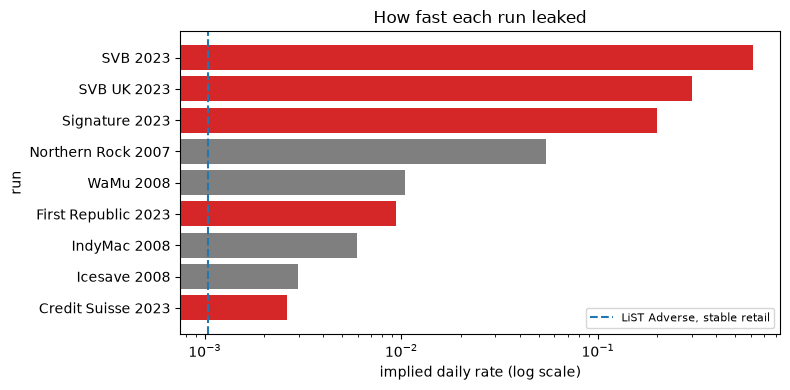

In [6]:
# Draw the implied daily rate of each run on a logarithmic axis, the runs of 2023 in red
names = [f"{run.bank} {run.year}" for run in table]
colors = ["tab:red" if run.year == 2023 else "tab:gray" for run in table]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(names, implied, color=colors)
ax.axvline(q, color="tab:blue", linestyle="--", label="LiST Adverse, stable retail")
ax.set_xscale("log")
ax.set_xlabel("implied daily rate (log scale)")
ax.set_ylabel("run")
ax.set_title("How fast each run leaked")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The bars put very different runs on one scale. The dashed line is the stable retail rate of the LiST, 0.00103258 a day, and it lies to the left of every bar: even the slowest run of the table, Credit Suisse with 0.002616 a day, leaks faster than the stress test assumes for its most stable class. The five runs of 2023 in red spread over two orders of magnitude, from 0.009334 for First Republic to 0.612702 for SVB, and the fastest is 234.2 times the slowest. The figure compares rates, not exposures: each run had its own share of insured deposits, which the table does not give.

### Step 3: the outflows of a segment, day by day

When the rate changes with the state of the stress, the cumulative outflow is the product of the daily survivals, and the outflow of day $d$ is the stock still deposited times that day's rate:

$$F(n) = 1 - \prod_{d \le n} (1 - q_d), \qquad O_s(d) = B_s \prod_{k < d} (1 - q_k)\; q_d$$

$B_s$ is the opening balance of segment $s$. The engine has `cumulative_outflow_path` for the first and `behavioural_outflows` for the second (it multiplies the stock share of the day before by the rate, so it never subtracts two nearly equal numbers). The next cell rebuilds the retail insured segment of the document from its opening balance and its 125 daily rates, and prints the first three days as the intermediates.

In [7]:
# Rebuild the retail insured segment from its opening balance and its daily rates
from riskvalidation.liquidity.ladder import behavioural_outflows
from riskvalidation.liquidity.runoff import cumulative_outflow_path

segments = {s["segment"]: s for s in out["path"]["ladder"]["segments"]}
retail = segments["retail-insured"]
opening = np.array([retail["opening_balance"]])
rates = np.array([retail["daily_rates"]])
flows = behavioural_outflows(opening, rates)[0]
cumulative = cumulative_outflow_path(rates[0])

print("opening balance (USD thousands):", opening[0], "| days:", rates.shape[1])
print("daily rate of day 1:", rates[0, 0])
survival = 1.0
for day in range(3):
    outflow = opening[0] * survival * rates[0, day]
    print(f"day {day + 1} | still deposited {survival:.8f} | rate {rates[0, day]}")
    print(f"      outflow {outflow:.4f} | engine {flows[day]:.4f}")
    survival *= 1.0 - rates[0, day]
print("cumulative share at day 125:", round(cumulative[-1], 6))

opening balance (USD thousands): 9990000.0 | days: 125
daily rate of day 1: 0.00373218
day 1 | still deposited 1.00000000 | rate 0.00373218
      outflow 37284.4782 | engine 37284.4782
day 2 | still deposited 0.99626782 | rate 0.00373218
      outflow 37145.3258 | engine 37145.3258
day 3 | still deposited 0.99254957 | rate 0.00373218
      outflow 37006.6928 | engine 37006.6928
cumulative share at day 125: 0.373368


The same two functions take a rate that changes. As an exploration, not a committed scenario, the next cell doubles the rate of this segment from day 11 to day 20 and compares the cumulative outflow at day 125 with the constant case: the path matters, not only the average rate.

In [8]:
# A rate that doubles on days 11 to 20 (an exploration, not a committed scenario)
what_if = rates[0].copy()
what_if[10:20] *= 2.0
path_what_if = cumulative_outflow_path(what_if)
extra = opening[0] * (path_what_if[-1] - cumulative[-1])

print("cumulative outflow at day 125, constant rate:", round(cumulative[-1], 6))
print("cumulative outflow at day 125, doubled on days 11 to 20:", round(path_what_if[-1], 6))
print("extra outflow (USD thousands):", round(extra, 2))

cumulative outflow at day 125, constant rate: 0.373368
cumulative outflow at day 125, doubled on days 11 to 20: 0.39645
extra outflow (USD thousands): 230597.75


The next cell draws both paths: the outflow of each day on the left and the cumulative share of the segment on the right.

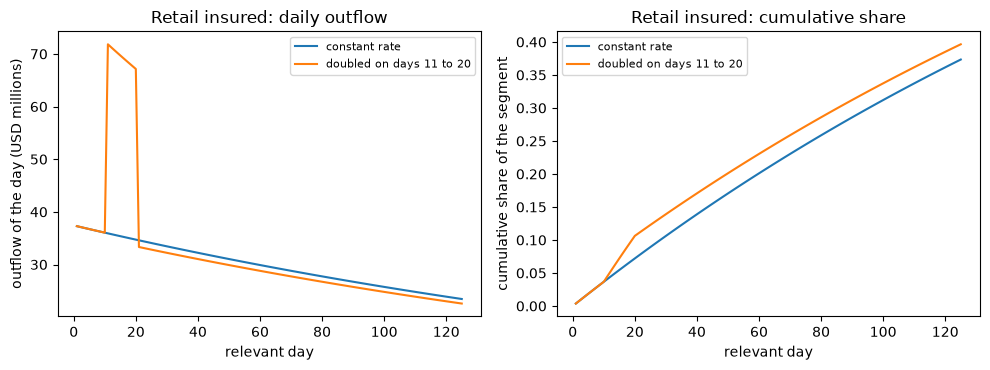

In [9]:
# Draw the daily outflow and the cumulative share of the segment, constant rate and doubled on days 11 to 20
days = np.arange(1, rates.shape[1] + 1)
flows_what_if = behavioural_outflows(opening, what_if[None, :])[0]
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
left.plot(days, flows / 1e3, label="constant rate")
left.plot(days, flows_what_if / 1e3, label="doubled on days 11 to 20")
left.set_xlabel("relevant day")
left.set_ylabel("outflow of the day (USD millions)")
left.set_title("Retail insured: daily outflow")
left.legend(fontsize=8)
right.plot(days, cumulative, label="constant rate")
right.plot(days, path_what_if, label="doubled on days 11 to 20")
right.set_xlabel("relevant day")
right.set_ylabel("cumulative share of the segment")
right.set_title("Retail insured: cumulative share")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

The left panel shows the daily outflow shrinking slowly under the constant rate (37,284.48 thousand USD on day 1 and 37,145.33 on day 2, because the stock shrinks while the rate does not), jumping while the rate is doubled in days 11 to 20, and then returning just below the base path, because there is less stock left to leak. The right panel shows the consequence: the cumulative share ends at 0.39645 instead of 0.373368, which is 230,597.75 thousand USD more. A temporary doubling leaves a permanent mark, so the path of the rate matters and not only its average. The figure is an exploration, not a committed scenario.

### Step 4: contractual roll-off and the financial deposits

Not every liability is open-maturity. A contractual liability leaves the balance sheet when it matures, and the LiST applies to each maturing flow a constant outflow rate by class (Table 3.2, paragraph 94); the rest is assumed rolled over and stays beyond the horizon. Maturing interbank and other financial deposits do not roll over at all (paragraph 98, rate 1). The engine has `contractual_rolloff` and `financial_no_rollover`; the sight deposits of financial customers flow out in full on the first relevant day (paragraph 111), which is how the document runs its `financial` segment. The next cell shows the three rules.

In [10]:
# Contractual roll-off of a maturing flow, the no-roll-over rule and the financial segment of the document
from riskvalidation.liquidity.runoff import contractual_rolloff, financial_no_rollover

maturing = np.array([100.0, 50.0])
stable_rate = LIST_PARAMETERS["adverse"]["contractual_outflow"]["stable-retail"]
print("contractual outflow rate of stable retail, Adverse:", stable_rate)
print("a flow of [100, 50] maturing, stable retail:", contractual_rolloff(maturing, stable_rate))
print("the same flow, a financial deposit:", financial_no_rollover(maturing))

financial = segments["financial"]
horizon = len(financial["outflows"])
full = behavioural_outflows(np.array([financial["opening_balance"]]), np.ones((1, horizon)))[0]
print("financial segment, rate 1 every day, first three days:", full[:3])

contractual outflow rate of stable retail, Adverse: 0.18
a flow of [100, 50] maturing, stable retail: [18.  9.]
the same flow, a financial deposit: [100.  50.]
financial segment, rate 1 every day, first three days: [13899000.        0.        0.]


### Step 5: the back-test against an observed run

A run-off assumption can be tested against what happened. The test `liq.runoff_adequacy_back_test` compares the modelled outflow share with the realised one (Basel assumptions against the observed rate):

$$\text{ratio} = \frac{\text{modelled share}}{\text{realised share}}, \qquad \text{shortfall} = \text{realised share} - \text{modelled share}$$

It is a descriptive score on one real event, with no p-value. The light is a Contraste internal gate (green from a ratio of 0.8, amber from 0.5, red below), not a regulatory threshold. The realised share is the Federal Reserve's "roughly 85 percent" of the deposit base in two days (Federal Reserve, 2023); the modelled share is the sum of the first two days of the segment outflows of the document over the model's deposit base. The next cell computes the modelled share and calls the test.

In [11]:
# Back-test the first two days of the LiST Adverse outflows against the observed 85 percent in two days
from riskvalidation.validation.liquidity import runoff_adequacy_back_test

evaluation = out["scoring"]
base_deposits = evaluation["model_deposit_base"]
first_two_days = sum(sum(s["outflows"][:2]) for s in out["path"]["ladder"]["segments"])
modelled = first_two_days / base_deposits
board = evaluation["denominators"][0]
test = runoff_adequacy_back_test(
    modelled, board["realised_share"], compared_at="event-horizon", denominator=board["id"]
)

print("outflow of the first two days (USD thousands):", round(first_two_days, 2))
print("deposit base of the model (USD thousands):", base_deposits)
print("modelled share:", round(modelled, 6), "| realised share:", board["realised_share"])
print("ratio:", round(test.statistic, 6), "| shortfall:", round(test.metric, 6), "| light:", test.light.value)
# the same test at the 30-day model horizon of the LCR variant, as the product baked it
for row in standard["tests"]:
    if row["test_id"] == "liq.runoff_adequacy_back_test":
        ratio = round(row["statistic"], 6)
        print("30-day model horizon |", row["segment"], "| ratio:", ratio, "| light:", row["light"])

outflow of the first two days (USD thousands): 16053789.14
deposit base of the model (USD thousands): 175481000.0
modelled share: 0.091484 | realised share: 0.85
ratio: 0.107629 | shortfall: 0.758516 | light: red
30-day model horizon | board-stated-share | ratio: 0.506405 | light: amber
30-day model horizon | call-report-dep | ratio: 0.539534 | light: amber


The next cell draws the central lesson of the notebook: the smooth LiST Adverse cumulative outflows of three classes over 125 days, and the nine runs of Table A.1 as points at their own horizon.

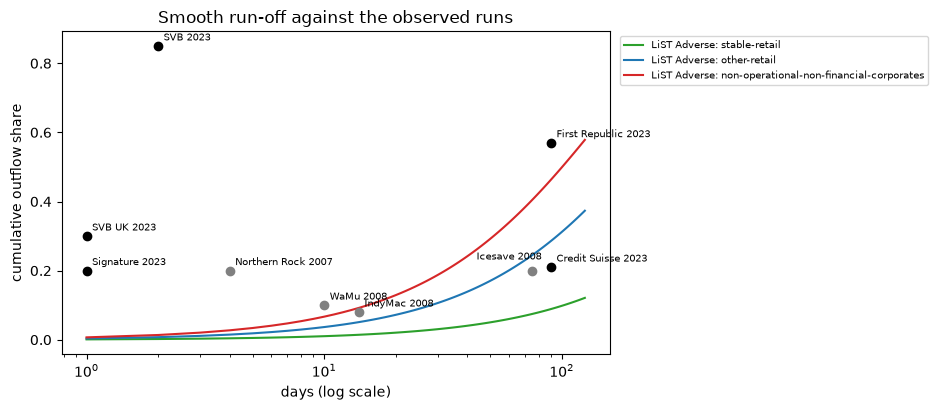

In [12]:
# Draw the smooth LiST Adverse curves against the runs of Table A.1
fig, ax = plt.subplots(figsize=(9.5, 4.2))
days = np.arange(1, 126)
open_maturity = LIST_PARAMETERS["adverse"]["open_maturity"]
classes = (
    ("stable-retail", "tab:green"),
    ("other-retail", "tab:blue"),
    ("non-operational-non-financial-corporates", "tab:red"),
)
for name, color in classes:
    curve = cumulative_outflow_constant(open_maturity[name], days)
    ax.plot(days, curve, color=color, label=f"LiST Adverse: {name}")
for run in TABLE_A1:
    ax.scatter(run.days, run.outflow_share, color="black" if run.year == 2023 else "gray", zorder=3)
    offset = (-40, 8) if run.row_id == "icesave-2008" else (4, 4)
    label = f"{run.bank} {run.year}"
    ax.annotate(label, (run.days, run.outflow_share), textcoords="offset points", xytext=offset, fontsize=7)
ax.set_xscale("log")
ax.set_xlabel("days (log scale)")
ax.set_ylabel("cumulative outflow share")
ax.set_title("Smooth run-off against the observed runs")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.tight_layout()
plt.show()

Every smooth curve sits below four of the five runs of 2023 (SVB, SVB UK, Signature and First Republic); only the run of Credit Suisse, 90 days long, lies below the two faster curves. The slow runs of 2008 are covered with room to spare. The rates of the stress test describe a slow leak, and the fast runs of 2023 describe something else. The logarithmic axis compresses time, so the runs of one and two days sit at the left edge, where the curves have barely started: this is where the distance between the assumption and the event is largest.

## Results

**Answer:** A constant daily rate of 0.00103258 (stable retail under LiST Adverse) takes 0.12114837 of the deposits out in 125 days, the 12.11% of the ECB's own example. That smooth assumption is far from the runs of 2023: the implied daily rate of SVB, 85% in 2 days, is 0.612702, 234.2 times the slowest run of Table A.1, and the LiST Adverse outflow of the first two days is 0.091484 of the deposit base against the 0.85 observed, a ratio of 0.107629.

- **The golden.** The base, its 125th power and the complement are 0.99896742, 0.87885163 and 0.12114837, and the engine returns the same value. The product's golden test reports a distance of about 3.7e-07 from the printed 12.11%.
- **The inverse.** The implied daily rate of the runs goes from 0.002616 (Credit Suisse, 21% in 90 days) to 0.612702 (SVB, 85% in 2 days): the fastest is 234.2 times the slowest. The stable retail rate of the note, 0.00103258, is below even the slowest run of the table.
- **The segment.** The retail insured segment loses 37,284.48 thousand USD on day 1 and 37,145.33 on day 2 (the stock shrinks, the rate does not) and 0.373368 of its stock after 125 days. Doubling the rate on days 11 to 20 raises the cumulative outflow from 0.373368 to 0.39645, which is 230,597.75 thousand USD more. A contractual flow of [100, 50] of stable retail rolls off as [18, 9], the same flow of a financial deposit leaves in full, and the financial segment of the document leaves 13,899,000 thousand USD on day 1.
- **The back-test.** The LiST Adverse outflow of the first two days is 16,053,789.14 thousand USD, 0.091484 of the deposit base of the model. Against the 0.85 of the Federal Reserve this is a ratio of 0.107629 and a shortfall of 0.758516, red under the internal gates. Against the 30-day LCR outflows (the model horizon) the two baked rows are amber, with ratios of 0.506405 and 0.539534. The smooth assumption is far from the event it is asked to cover; the rows describe one real event with synthetic deposits, one observation and no p-value, so they show the size of the gap, not a probability.

What this notebook does not show: how the CBC that these outflows are set against is built (notebook 03), how the segments are composed into a scenario (notebook 04) or what the LCR says (notebook 05).

## Summary

- A constant daily rate $q$ compounds to $1-(1-q)^n$ after $n$ days; the LiST golden (12.11% after 125 days at 0.103258% a day) is reproduced to the printed precision.
- Its inverse turns any observed run into a daily rate, which puts very different runs on one scale.
- A segment's outflows are the stock still deposited times the daily rate; contractual liabilities roll off by class and financial deposits do not roll over.
- A back-test sets the modelled outflow against an observed run; under the product's internal gates the LiST Adverse outflow of the first two days is red against the 85% of March 2023.

**What to try next.** Change the day and the rate of the exploration (a doubling on days 1 to 5) and see how much of the cumulative outflow comes from the first week; then continue with notebook 03.

## References

- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, methodological note (2019-02-06), Tables 3.2 and 3.3 and paragraphs 94, 98, 107 and 111. https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.ECB_sensitivity_analysis_of_liquidity_risk-stress_test_2019-methodological_note_20190206~6771e88926.en.pdf
- BCBS (2023), Report on the 2023 banking turmoil, Box A, Table A.1. https://www.bis.org/bcbs/publ/d555.htm
- Federal Reserve Board (2023-04-28), Review of the Federal Reserve's Supervision and Regulation of Silicon Valley Bank. https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf